# Predicting how long a health commodity order takes to arrive

**Mission:** My mission is to improve healthcare delivery in Africa by building software that helps clinics and health programs serve their communities better.

**Problem and use case:** Clinics can only treat patients if medicines and lab supplies are in stock. Medical stores like Rwanda Medical Supply order them months ahead through donor supply chains, and if they guess the delivery time wrong, facilities run out. I predict the **order cycle time**: the number of days from when an order is entered until it is delivered. A supply planner would use it to decide when to reorder.

**Dataset:** USAID GHSC-PSM Health Commodity Delivery Dataset, with one row per order line delivered by USAID's health supply chain program from 2016 to 2024 (43,396 rows, 104 columns, 96 countries). The data.usaid.gov site went offline in 2025, so I use the archived copy of the official CSV.

- Original page: https://data.usaid.gov/Health/USAID-GHSC-PSM-Health-Commodity-Delivery-Dataset/tikn-bfy4
- Archived CSV: https://web.archive.org/web/20250129194228/https://data.usaid.gov/api/views/tikn-bfy4/rows.csv?accessType=DOWNLOAD

I train on all countries because Rwanda alone has only about 1,000 rows. More than 80% of the orders are for African countries that get the same products through the same program, and country is one of the inputs.

In [1]:
import os
import urllib.request

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
RANDOM_STATE = 42

## 1. Loading the data

The notebook downloads the CSV (46 MB) the first time and reads the local copy after that.

In [2]:
# "id_" in the link gives the original file, without the Wayback Machine page around it
DATA_URL = "https://web.archive.org/web/20250129194228id_/https://data.usaid.gov/api/views/tikn-bfy4/rows.csv?accessType=DOWNLOAD"
DATA_FILE = "ghsc_psm_deliveries.csv"

if not os.path.exists(DATA_FILE):
    print("Downloading the dataset...")
    urllib.request.urlretrieve(DATA_URL, DATA_FILE)

raw = pd.read_csv(DATA_FILE, low_memory=False)
print(raw.shape)
raw.head(3)

(43396, 104)


,ROPOLine,Task Order,Condom Adjusted Task Order,Country,RO Number,PO DO IO Number,Order Number,Prime Line Number,Status Name,TLP Indicator,Order Type,Fulfillment Method,Transportation Mode,Item Tracer Category,Product Category,...,Max Pick Up Date,Max Ship Date,Max Departure Date,Max Arrival Date,Order Cycle Time,RO Validation,Sourcing and Planning,USAID Approval,Process PO/DO,Manufacture,Pick Up,Deliver,Quality Assurance,Reason Code,Reason Code Duration
0,RO10026301PO100041611,TO1,TO1,Haiti,RO10026301,PO10004161,PO10004161,1,Shipment Delivered,DCP,Purchase Order,Direct Drop,Land,Laboratory,Laboratory Reagents,...,NaN,"Thursday, October 5, 2017",NaN,NaN,98,NaN,NaN,0.0,35.0,NaN,NaN,NaN,NaN,NaN,NaN
1,RO10043181PO100076996,TO1,TO1,Zambia,RO10043181,PO10007699,PO10007699,6,Shipment Delivered,DCP,Purchase Order,Direct Drop,Land,Laboratory,Laboratory Reagents,...,NaN,"Wednesday, July 18, 2018",NaN,NaN,245,NaN,NaN,3.0,35.0,NaN,NaN,NaN,NaN,NaN,NaN
2,RO10022196PO100016001,TO1,TO1,Mozambique,RO10022196,PO10001600,PO10001600,1,Shipment Delivered,DCP,Purchase Order,Direct Drop,Land,Laboratory,Laboratory Reagents,...,NaN,"Tuesday, June 6, 2017",NaN,NaN,128,NaN,NaN,13.0,209.0,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
cols_to_look_at = ["Country", "Order Type", "Fulfillment Method", "Transportation Mode", "Product Category",
                   "D365 Health Element", "Vendor Incoterm", "Destination Incoterm", "Ordered Quantity",
                   "Illustrative Price", "Estimated Lead Time in Days", "Order Entry Date", "Order Cycle Time"]
raw[cols_to_look_at].info()

<class 'pandas.DataFrame'>
RangeIndex: 43396 entries, 0 to 43395
Data columns (total 13 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Country                      43396 non-null  str    
 1   Order Type                   43396 non-null  str    
 2   Fulfillment Method           43396 non-null  str    
 3   Transportation Mode          43396 non-null  str    
 4   Product Category             43396 non-null  str    
 5   D365 Health Element          42842 non-null  str    
 6   Vendor Incoterm              39209 non-null  str    
 7   Destination Incoterm         37533 non-null  str    
 8   Ordered Quantity             43396 non-null  int64  
 9   Illustrative Price           43271 non-null  float64
 10  Estimated Lead Time in Days  31725 non-null  float64
 11  Order Entry Date             43396 non-null  str    
 12  Order Cycle Time             43396 non-null  int64  
dtypes: float64(2), int64(2), st

Most of the 104 columns are ID numbers, or dates and durations that only exist after delivery, so a planner doesn't have them when ordering. `Order Cycle Time` is already in days, so it is my target.

## 2. Cleaning

In [4]:
df = raw.copy()

# only orders that were actually delivered, and cycle times that make sense
df = df[df["Status Name"] == "Shipment Delivered"]
df = df[df["Order Cycle Time"] > 0]
print("rows after removing undelivered / negative cycle times:", len(df))

# the dates look like "Thursday, November 17, 2016"
date_format = "%A, %B %d, %Y"
order_date = pd.to_datetime(df["Order Entry Date"], format=date_format)
delivery_date = pd.to_datetime(df["Latest Actual Delivery Date"], format=date_format)
print("last order entered:", order_date.max().date(), "| last delivery:", delivery_date.max().date())

# cycle time of the most recent orders, by the quarter the order was entered
recent_check = df.groupby(order_date.dt.to_period("Q"))["Order Cycle Time"].agg(["count", "median", "max"])
recent_check.tail(8)

rows after removing undelivered / negative cycle times: 43121
last order entered: 2024-04-25 | last delivery: 2024-07-26


,count,median,max
Order Entry Date,,,
2022Q3,1423,243.0,725
2022Q4,1464,231.0,572
2023Q1,686,237.0,534
2023Q2,788,206.0,464
2023Q3,1039,191.0,370
2023Q4,869,178.0,298
2024Q1,353,122.0,201
2024Q2,15,53.0,99


The last delivery in the file is on 26 July 2024, so that is when the data was exported. In the last four quarters the maximum cycle time is only 370, 298, 201 and 99 days, compared with 725 a year earlier, and the median drops too.

These orders are not really faster. A recent order can only be in the file if it has already arrived, so the slow ones are missing. To stop the model from learning that recent orders are fast, I remove every order entered in the last 365 days before the last delivery.

In [5]:
# remove orders entered in the last 365 days before the last delivery in the file
cutoff = delivery_date.max() - pd.Timedelta(days=365)
is_recent = order_date > cutoff
print("cutoff date:", cutoff.date(), "| recent orders removed:", is_recent.sum())
df = df[~is_recent]
order_date = order_date[~is_recent]

data = pd.DataFrame({
    "country": df["Country"],
    "order_type": df["Order Type"],
    "transport_mode": df["Transportation Mode"],
    "product_category": df["Product Category"],
    "health_element": df["D365 Health Element"],
    "vendor_incoterm": df["Vendor Incoterm"],
    "destination_incoterm": df["Destination Incoterm"],
    "ordered_quantity": df["Ordered Quantity"],
    "unit_price": df["Illustrative Price"],
    "est_lead_time_days": df["Estimated Lead Time in Days"],
    "order_year": order_date.dt.year,
    "order_month": order_date.dt.month,
    "order_cycle_days": df["Order Cycle Time"],
})

# columns I only keep for now to look at in the heatmap (they get dropped later)
leaky = df[["Shipped Quantity", "Manufacture", "Pick Up", "Deliver"]].rename(columns={
    "Shipped Quantity": "shipped_quantity", "Manufacture": "manufacture_days",
    "Pick Up": "pickup_days", "Deliver": "deliver_days"})

data.isna().sum()

cutoff date: 2023-07-27 | recent orders removed: 1964


country                     0
order_type                  0
transport_mode              0
product_category            0
health_element            520
vendor_incoterm          4085
destination_incoterm     5758
ordered_quantity            0
unit_price                125
est_lead_time_days      11433
order_year                  0
order_month                 0
order_cycle_days            0
dtype: int64

Other cleaning decisions:

- `est_lead_time_days` (the lead time estimated when the order is placed) is missing in about a quarter of the rows. It is my strongest feature, so I drop those rows instead of filling in a made-up value. About 29,700 rows are left.
- `vendor_incoterm` has 300+ messy spellings like `FCA - SUWANEE`. I keep the first three letters, which are the real incoterm.
- Categories that appear only a few times go into "Other", so one-hot encoding doesn't create many almost empty columns.

In [6]:
data["vendor_incoterm"] = data["vendor_incoterm"].str[:3]


def group_rare(col, min_count, other_label="Other"):
    counts = col.value_counts()
    keep = counts[counts >= min_count].index
    return col.where(col.isin(keep), other_label)


for c in ["vendor_incoterm", "destination_incoterm", "health_element"]:
    data[c] = data[c].fillna("Unknown")

data["country"] = group_rare(data["country"], 30)
data["product_category"] = group_rare(data["product_category"], 30, other_label="Others")
data["vendor_incoterm"] = group_rare(data["vendor_incoterm"], 100)
data["destination_incoterm"] = group_rare(data["destination_incoterm"], 100)
data["health_element"] = group_rare(data["health_element"], 100)

keep_rows = data["est_lead_time_days"].notna() & data["unit_price"].notna() & (data["ordered_quantity"] > 0)
data = data[keep_rows]
leaky = leaky[keep_rows]
print(data.shape)
data.describe().round(1)

(29721, 13)


,ordered_quantity,unit_price,est_lead_time_days,order_year,order_month,order_cycle_days
count,29721.0,29721.0,29721.0,29721.0,29721.0,29721.0
mean,26904.3,517.5,163.8,2019.9,6.7,251.9
std,110592.1,4762.1,85.2,1.7,3.3,129.0
min,1.0,0.0,0.0,2016.0,1.0,1.0
25%,24.0,7.5,105.0,2018.0,4.0,159.0
50%,200.0,44.9,147.0,2020.0,7.0,230.0
75%,3708.0,180.0,210.0,2021.0,9.0,324.0
max,2890944.0,193455.0,1260.0,2023.0,12.0,1164.0


## 3. Exploring the data

### Distribution of the target

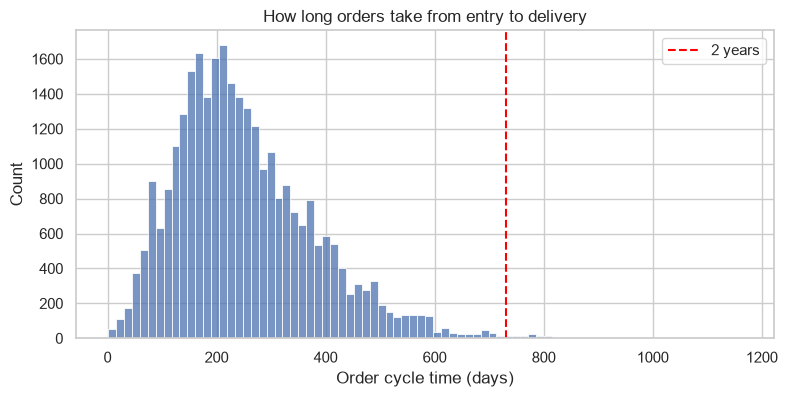

median: 230.0 | skew: 0.98
orders over 2 years: 119


In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data["order_cycle_days"], bins=80, ax=ax)
ax.axvline(730, color="red", linestyle="--", label="2 years")
ax.set_xlabel("Order cycle time (days)")
ax.set_title("How long orders take from entry to delivery")
ax.legend()
plt.show()

print("median:", data["order_cycle_days"].median(), "| skew:", round(data["order_cycle_days"].skew(), 2))
print("orders over 2 years:", (data["order_cycle_days"] > 730).sum())

Most orders take between 100 and 400 days, with a median of 230 days (more than 7 months). There is a long right tail, and 119 orders take more than 2 years. I removed those because they are rare and would dominate the squared error. I kept the target in days without a log, because the skew is not extreme and an error in days is easier to explain.

In [8]:
data = data[data["order_cycle_days"] <= 730]
leaky = leaky.loc[data.index]
print(data.shape)

(29602, 13)


### Quantity and price

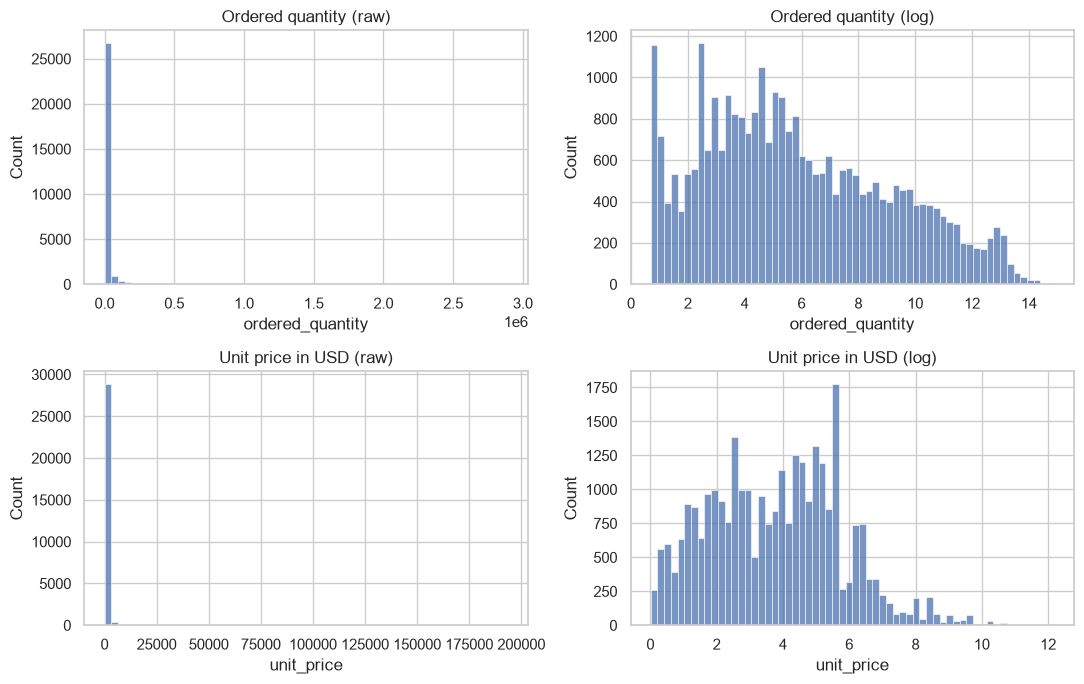

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
sns.histplot(data["ordered_quantity"], bins=60, ax=axes[0, 0])
axes[0, 0].set_title("Ordered quantity (raw)")
sns.histplot(np.log1p(data["ordered_quantity"]), bins=60, ax=axes[0, 1])
axes[0, 1].set_title("Ordered quantity (log)")
sns.histplot(data["unit_price"], bins=60, ax=axes[1, 0])
axes[1, 0].set_title("Unit price in USD (raw)")
sns.histplot(np.log1p(data["unit_price"]), bins=60, ax=axes[1, 1])
axes[1, 1].set_title("Unit price in USD (log)")
plt.tight_layout()
plt.show()

Quantity and price are extremely skewed, with a few orders up to almost 3 million units or $190,000 per unit. After a log transform both are spread out much better, so I apply `log1p` to these two columns before scaling. This mostly helps the linear models.

### Correlation heatmap

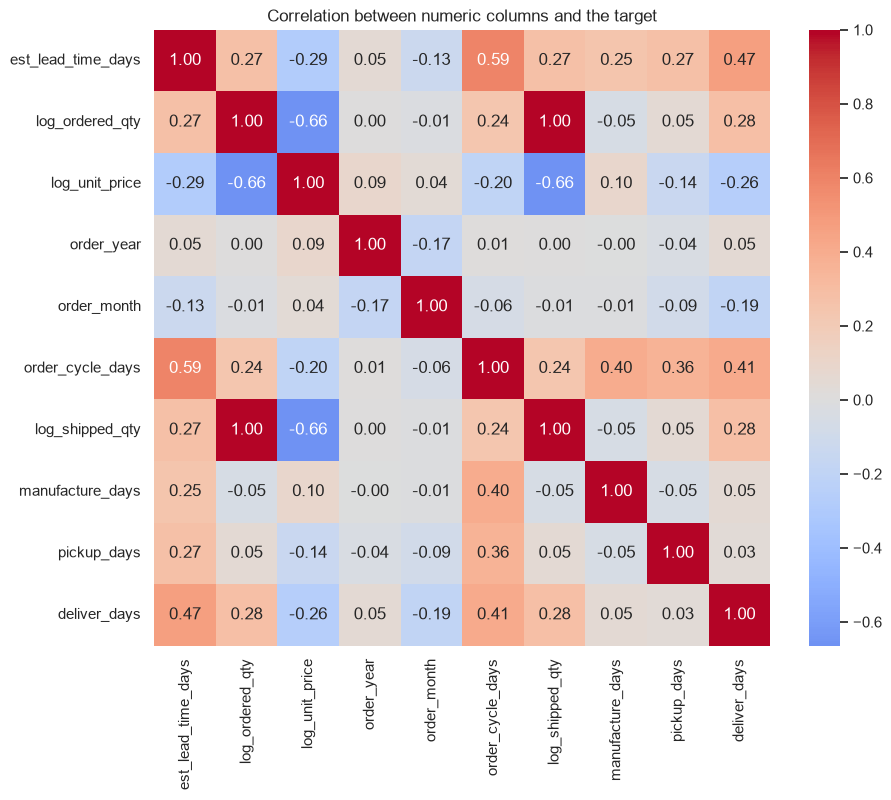

In [10]:
heat = data[["est_lead_time_days", "ordered_quantity", "unit_price", "order_year", "order_month", "order_cycle_days"]].copy()
heat["ordered_quantity"] = np.log1p(heat["ordered_quantity"])
heat["unit_price"] = np.log1p(heat["unit_price"])
heat["shipped_quantity"] = np.log1p(leaky["shipped_quantity"])
heat["manufacture_days"] = leaky["manufacture_days"]
heat["pickup_days"] = leaky["pickup_days"]
heat["deliver_days"] = leaky["deliver_days"]
heat = heat.rename(columns={"ordered_quantity": "log_ordered_qty", "unit_price": "log_unit_price",
                            "shipped_quantity": "log_shipped_qty"})

plt.figure(figsize=(10, 8))
sns.heatmap(heat.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation between numeric columns and the target")
plt.show()

`est_lead_time_days` has the strongest correlation with the target (0.59), so I use it for the scatter plots later. Log quantity (0.24) and log price (-0.20) are weaker but I keep them.

Because of this plot I dropped the shipped quantity (correlation of 1.00 with the ordered quantity) and the stage durations. The durations correlate with the target (0.36 to 0.41), but they are parts of the cycle time and only exist after delivery, so they would leak the answer. I kept `order_year` and `order_month` even with almost no linear correlation, because delays can change over time in a way that is not a straight line.

### Does the target change across the categorical columns?

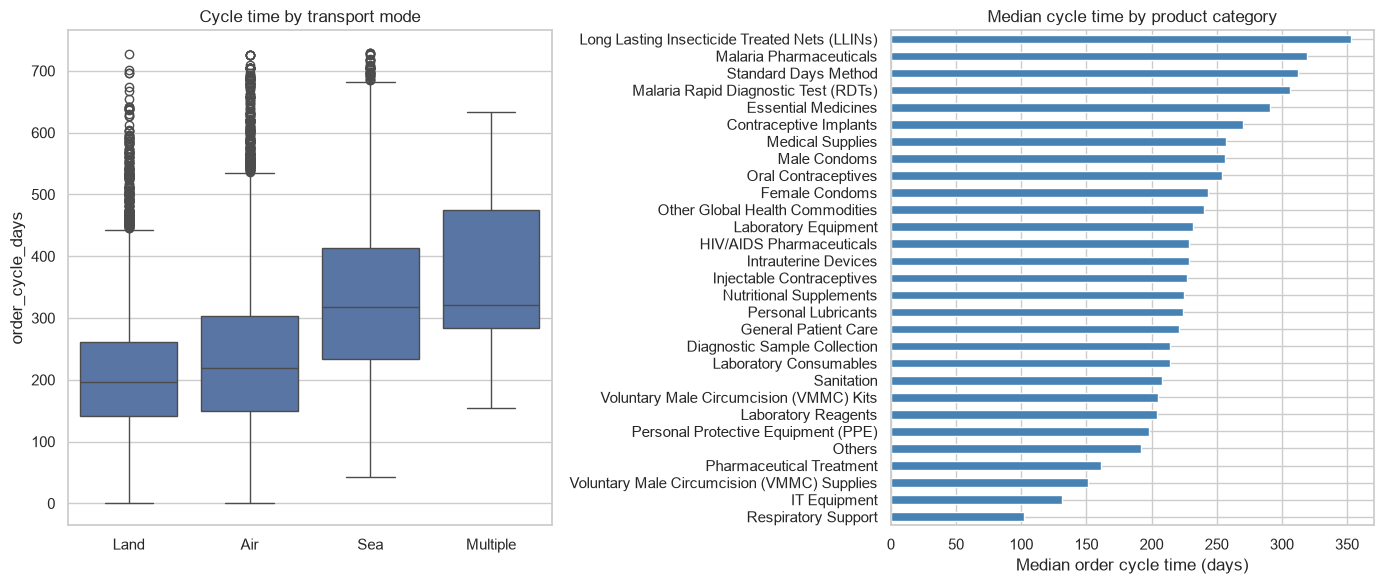

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.boxplot(data=data, x="transport_mode", y="order_cycle_days", ax=axes[0],
            order=["Land", "Air", "Sea", "Multiple"])
axes[0].set_title("Cycle time by transport mode")
axes[0].set_xlabel("")

by_product = data.groupby("product_category")["order_cycle_days"].median().sort_values()
by_product.plot(kind="barh", ax=axes[1], color="steelblue")
axes[1].set_title("Median cycle time by product category")
axes[1].set_xlabel("Median order cycle time (days)")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

Sea and multiple-mode orders have a median above 300 days, while land and air are around 200. Product category matters too, from about 100 days for respiratory support to about 350 for mosquito nets (LLINs). So I keep the categorical columns and one-hot encode them. Since these categories have no natural order, I expected the tree models to do better.

## 4. Feature engineering

**Dropped:**
- ID columns (order numbers, product IDs): only identifiers.
- Everything only known after delivery (actual dates, shipped quantity, days late, on-time flags, stage durations): it would leak the answer.
- `Fulfillment Method`: same information as `Order Type`.
- `Product_Name`: 4,730 different values. `Product Category` covers it.
- `Delivery Progress`: same value in every row.

**Kept (12 inputs):** country, order type, transport mode, product category, health element, vendor incoterm, destination incoterm (categorical) and ordered quantity, unit price, estimated lead time, order year, order month (numeric).

**Most important:** in the heatmap, estimated lead time is the strongest numeric feature. In the plots above, transport mode and product category also change the cycle time a lot.

In [12]:
cat_features = ["country", "order_type", "transport_mode", "product_category", "health_element",
                "vendor_incoterm", "destination_incoterm"]
log_features = ["ordered_quantity", "unit_price"]
num_features = ["est_lead_time_days", "order_year", "order_month"]
FEATURES = cat_features + log_features + num_features
TARGET = "order_cycle_days"

data = data[FEATURES + [TARGET]].reset_index(drop=True)
print(len(FEATURES), "input features,", len(data), "rows")
data.head()

12 input features, 29602 rows


,country,order_type,transport_mode,product_category,health_element,vendor_incoterm,destination_incoterm,ordered_quantity,unit_price,est_lead_time_days,order_year,order_month,order_cycle_days
0,Zambia,Purchase Order,Land,Laboratory Reagents,HIV/AIDS,DDP,DDP,191,348.01,91.0,2017,11,245
1,Zambia,Purchase Order,Land,Laboratory Reagents,HIV/AIDS,DDP,DDP,210,137.00,140.0,2018,8,501
2,Mozambique,Purchase Order,Land,Laboratory Consumables,HIV/AIDS,DDP,DDP,306,260.00,154.0,2017,10,151
3,Uganda,Purchase Order,Land,Laboratory Consumables,HIV/AIDS,DDP,DDP,150,260.00,70.0,2017,10,153
4,Mozambique,Purchase Order,Land,Laboratory Consumables,HIV/AIDS,DDP,Unknown,65,260.00,0.0,2017,6,197


## 5. Train/test split and standardizing

I split the data 80/20. Categorical columns are one-hot encoded, quantity and price get a log, and all numeric columns are standardized. The preprocessing is fitted on the training set only, so the test set does not influence the scaling. The log is inside the preprocessing so the saved model does it by itself and the API can send raw values.

In [13]:
X = data[FEATURES]
y = data[TARGET]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)


def make_preprocessor():
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_features),
        ("log", Pipeline([("log", FunctionTransformer(np.log1p)),
                          ("scale", StandardScaler())]), log_features),
        ("num", StandardScaler(), num_features),
    ])


preprocessor = make_preprocessor()
X_train_p = preprocessor.fit_transform(X_train)   # fit on train only
X_test_p = preprocessor.transform(X_test)
y_train_np = y_train.to_numpy()
y_test_np = y_test.to_numpy()

print("train:", X_train_p.shape, " test:", X_test_p.shape)

train: (23681, 117)  test: (5921, 117)


For tuning I take 20% of the training data as a validation set, so I never tune on the test set.

In [14]:
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=RANDOM_STATE)
tune_prep = make_preprocessor()
X_tr_p = tune_prep.fit_transform(X_tr)
X_val_p = tune_prep.transform(X_val)
y_tr_np, y_val_np = y_tr.to_numpy(), y_val.to_numpy()
print(X_tr_p.shape, X_val_p.shape)

(18944, 117) (4737, 117)


## 6. Model 1: linear regression with gradient descent (SGDRegressor)

scikit-learn does not save the loss after each epoch, so I call `partial_fit` in a loop. Each call is one pass over the training data, and after each one I save the MSE on both sets.

In [15]:
def train_sgd(X_a, y_a, X_b, y_b, lr, alpha, epochs):
    model = SGDRegressor(learning_rate="constant", eta0=lr, penalty="l2", alpha=alpha, random_state=RANDOM_STATE)
    losses_a, losses_b = [], []
    for epoch in range(epochs):
        model.partial_fit(X_a, y_a)
        losses_a.append(mean_squared_error(y_a, model.predict(X_a)))
        losses_b.append(mean_squared_error(y_b, model.predict(X_b)))
    return model, losses_a, losses_b

### Tuning the learning rate, regularization and epochs

I try 3 learning rates and 4 values of `alpha`, each for 60 epochs, and note the epoch with the lowest validation MSE.

In [16]:
learning_rates = [0.0001, 0.001, 0.01]
alphas = [0.0001, 0.001, 0.01, 0.1]
MAX_EPOCHS = 60

results = []
curves = {}
for lr in learning_rates:
    for alpha in alphas:
        _, tr_loss, val_loss = train_sgd(X_tr_p, y_tr_np, X_val_p, y_val_np, lr, alpha, MAX_EPOCHS)
        best_epoch = int(np.argmin(val_loss)) + 1
        results.append({"learning_rate": lr, "alpha": alpha, "best_epoch": best_epoch,
                        "val_mse_at_best_epoch": min(val_loss), "val_mse_after_60": val_loss[-1]})
        curves[(lr, alpha)] = val_loss

tuning = pd.DataFrame(results).sort_values("val_mse_at_best_epoch").reset_index(drop=True)
tuning.round({"val_mse_at_best_epoch": 1, "val_mse_after_60": 1})

,learning_rate,alpha,best_epoch,val_mse_at_best_epoch,val_mse_after_60
0,0.0001,0.0001,60,8751.7,8751.7
1,0.0001,0.0010,60,8757.8,8757.8
2,0.0001,0.0100,60,8832.0,8832.0
3,0.0010,0.0010,60,8849.5,8849.5
4,0.0010,0.0001,29,8851.2,8854.3
5,0.0010,0.0100,60,8951.3,8951.3
6,0.0001,0.1000,60,9257.5,9257.5
7,0.0100,0.0010,60,9313.5,9313.5
8,0.0100,0.0001,2,9324.2,9334.9
9,0.0100,0.0100,40,9349.8,9349.8


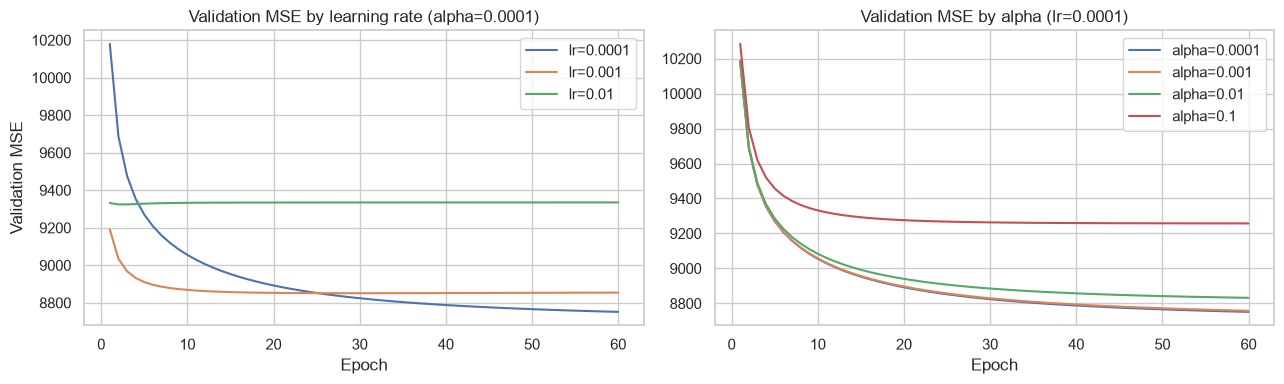

In [17]:
best_alpha = tuning.iloc[0]["alpha"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for lr in learning_rates:
    axes[0].plot(range(1, MAX_EPOCHS + 1), curves[(lr, best_alpha)], label=f"lr={lr}")
axes[0].set_title(f"Validation MSE by learning rate (alpha={best_alpha})")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Validation MSE")
axes[0].legend()

best_lr = tuning.iloc[0]["learning_rate"]
for alpha in alphas:
    axes[1].plot(range(1, MAX_EPOCHS + 1), curves[(best_lr, alpha)], label=f"alpha={alpha}")
axes[1].set_title(f"Validation MSE by alpha (lr={best_lr})")
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.tight_layout()
plt.show()

What I found:

- Learning rate: 0.01 is too big. The loss gets stuck around 9,300 from the first epoch. 0.001 drops fast but levels off around 8,850 after about 10 epochs. 0.0001 is slower at the start but keeps going down and ends the lowest (about 8,750), so I chose it.
- Regularization: alpha 0.0001 and 0.001 give almost the same loss. 0.1 is clearly worse (about 9,260) because the penalty shrinks the weights too much. The model is not overfitting, so more regularization does not help.
- Epochs: with lr 0.0001 the loss is still going down a little at epoch 60, but from epoch 40 to 60 it only improves by about 40. More epochs would barely change anything, so the final model trains for 60 epochs.

### Final SGD model and loss curve

I train the best setting on the full training set and store the train and test MSE after every epoch.

lr=0.0001, alpha=0.0001, epochs=60


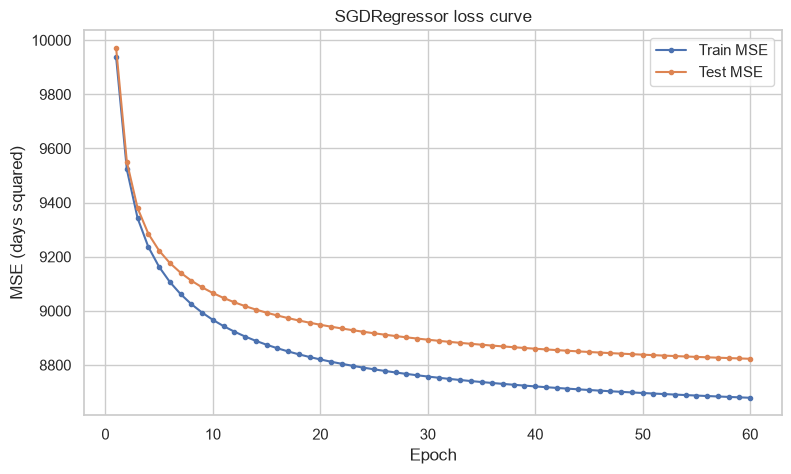

final train MSE: 8679.0 | final test MSE: 8823.0


In [18]:
best_lr = float(tuning.iloc[0]["learning_rate"])
best_alpha = float(tuning.iloc[0]["alpha"])
best_epochs = int(tuning.iloc[0]["best_epoch"])
print(f"lr={best_lr}, alpha={best_alpha}, epochs={best_epochs}")

sgd, sgd_train_loss, sgd_test_loss = train_sgd(X_train_p, y_train_np, X_test_p, y_test_np,
                                               best_lr, best_alpha, best_epochs)

plt.figure(figsize=(9, 5))
plt.plot(range(1, best_epochs + 1), sgd_train_loss, marker="o", markersize=3, label="Train MSE")
plt.plot(range(1, best_epochs + 1), sgd_test_loss, marker="o", markersize=3, label="Test MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE (days squared)")
plt.title("SGDRegressor loss curve")
plt.legend()
plt.show()

print("final train MSE:", round(sgd_train_loss[-1], 1), "| final test MSE:", round(sgd_test_loss[-1], 1))

Both curves drop fast in the first 10 epochs and then go down slowly, ending with train around 8,680 and test around 8,820. The test loss is only a little above the train loss, so the model is not overfitting. It is underfitting: a straight line cannot learn more from this data.

## 7. Model 2: linear regression (closed form)

The same model, but `LinearRegression` solves for the weights directly. If my SGD loop works, both should give a similar error.

In [19]:
lin = LinearRegression()
lin.fit(X_train_p, y_train_np)
print("train MSE:", round(mean_squared_error(y_train_np, lin.predict(X_train_p)), 1))
print("test MSE:", round(mean_squared_error(y_test_np, lin.predict(X_test_p)), 1))

train MSE: 8573.2
test MSE: 8764.4


## 8. Model 3: decision tree

A single tree overfits easily, so I compare values of `max_depth` on the validation set.

In [20]:
tree_scores = []
for depth in [4, 6, 8, 10, 12, 15, 20, None]:
    t = DecisionTreeRegressor(max_depth=depth, random_state=RANDOM_STATE).fit(X_tr_p, y_tr_np)
    tree_scores.append({"max_depth": "no limit" if depth is None else depth,
                        "train_mse": mean_squared_error(y_tr_np, t.predict(X_tr_p)),
                        "val_mse": mean_squared_error(y_val_np, t.predict(X_val_p))})
tree_scores = pd.DataFrame(tree_scores)
tree_scores.round(1)

,max_depth,train_mse,val_mse
0,4,9201.0,9318.6
1,6,8226.0,8479.0
2,8,7201.1,8070.1
3,10,6027.4,7460.0
4,12,4701.9,6870.6
5,15,3077.8,6371.8
6,20,1475.0,6329.9
7,no limit,201.4,6625.7


In [21]:
best_depth = tree_scores.loc[tree_scores["val_mse"].idxmin(), "max_depth"]
best_depth = None if best_depth == "no limit" else int(best_depth)
tree = DecisionTreeRegressor(max_depth=best_depth, random_state=RANDOM_STATE)
tree.fit(X_train_p, y_train_np)
print("max_depth:", best_depth)
print("train MSE:", round(mean_squared_error(y_train_np, tree.predict(X_train_p)), 1))
print("test MSE:", round(mean_squared_error(y_test_np, tree.predict(X_test_p)), 1))

max_depth: 20
train MSE: 1515.7
test MSE: 6113.0


With no depth limit the tree almost memorizes the training data (train MSE 201) but does worse on validation. Depth 20 had the lowest validation MSE, so I use it.

## 9. Model 4: random forest

A forest averages many trees, which should reduce the overfitting of a single tree. I try three depths and two values of `max_features`: all the columns at each split, or a random half of them.

I keep it at 50 trees because the API has to retrain this model on Render's free server, which is slow and has little memory.

In [22]:
forest_scores = []
for max_features in [1.0, 0.5]:
    for depth in [10, 20, 30]:
        f = RandomForestRegressor(n_estimators=50, max_depth=depth, max_features=max_features, min_samples_leaf=3,
                                  n_jobs=-1, random_state=RANDOM_STATE).fit(X_tr_p, y_tr_np)
        forest_scores.append({"max_features": max_features, "max_depth": depth,
                              "train_mse": mean_squared_error(y_tr_np, f.predict(X_tr_p)),
                              "val_mse": mean_squared_error(y_val_np, f.predict(X_val_p))})
forest_scores = pd.DataFrame(forest_scores)
forest_scores.round(1)

,max_features,max_depth,train_mse,val_mse
0,1.0,10,5388.0,6396.7
1,1.0,20,2254.5,4383.4
2,1.0,30,1829.7,4164.9
3,0.5,10,5530.1,6316.9
4,0.5,20,2436.6,4339.6
5,0.5,30,2051.8,4158.6


In [23]:
best_row = forest_scores.loc[forest_scores["val_mse"].idxmin()]
best_forest_depth = int(best_row["max_depth"])
best_max_features = float(best_row["max_features"])
print("best on validation: max_depth", best_forest_depth, "| max_features", best_max_features)

best on validation: max_depth 30 | max_features 0.5


Depth 30 with half the columns (`max_features=0.5`) has the lowest validation MSE, so I use those settings.

In [24]:
forest = RandomForestRegressor(n_estimators=50, max_depth=best_forest_depth, max_features=best_max_features,
                               min_samples_leaf=3, n_jobs=-1, random_state=RANDOM_STATE)
forest.fit(X_train_p, y_train_np)
print("train MSE:", round(mean_squared_error(y_train_np, forest.predict(X_train_p)), 1))
print("test MSE:", round(mean_squared_error(y_test_np, forest.predict(X_test_p)), 1))

train MSE: 1951.3
test MSE: 4121.9


## 10. Comparing the four models

All four are evaluated on the same test set.

In [25]:
models = {
    "Linear regression (SGD)": sgd,
    "Linear regression (closed form)": lin,
    "Decision tree": tree,
    "Random forest": forest,
}

rows = []
for name, m in models.items():
    test_pred = m.predict(X_test_p)
    rows.append({
        "model": name,
        "train_mse": mean_squared_error(y_train_np, m.predict(X_train_p)),
        "test_mse": mean_squared_error(y_test_np, test_pred),
        "test_rmse_days": np.sqrt(mean_squared_error(y_test_np, test_pred)),
        "test_r2": r2_score(y_test_np, test_pred),
    })

comparison = pd.DataFrame(rows).sort_values("test_mse").reset_index(drop=True)
best_name = comparison.loc[0, "model"]
print("Best model (lowest test MSE):", best_name)
comparison.round(3)

Best model (lowest test MSE): Random forest


,model,train_mse,test_mse,test_rmse_days,test_r2
0,Random forest,1951.280,4121.854,64.202,0.736
1,Decision tree,1515.725,6113.004,78.186,0.609
2,Linear regression (closed form),8573.177,8764.430,93.619,0.439
3,Linear regression (SGD),8679.003,8823.027,93.931,0.435


**The random forest has the lowest test MSE (4,122), so it is my best model and the one I save.** That is an RMSE of about 64 days.

- Linear models: both end at almost the same test MSE (8,764 and 8,823), so my SGD loop reached nearly the same answer as the closed form. They are limited because the effect of one category depends on the others. Sea shipping adds more days for some products and countries than for others, and a linear model can only add one fixed number per category.
- Decision tree: it learns those combinations (test MSE 6,113) but overfits a lot (train MSE 1,516).
- Random forest: averaging 50 trees keeps the combinations with less overfitting, and it is not bothered by the skewed columns.

## 11. Scatter plot before and after

For these two plots only, I fit a linear regression with one feature: `est_lead_time_days`, the one most correlated with the target.

most correlated feature: est_lead_time_days 0.593
test orders above 650 days (not shown): 1


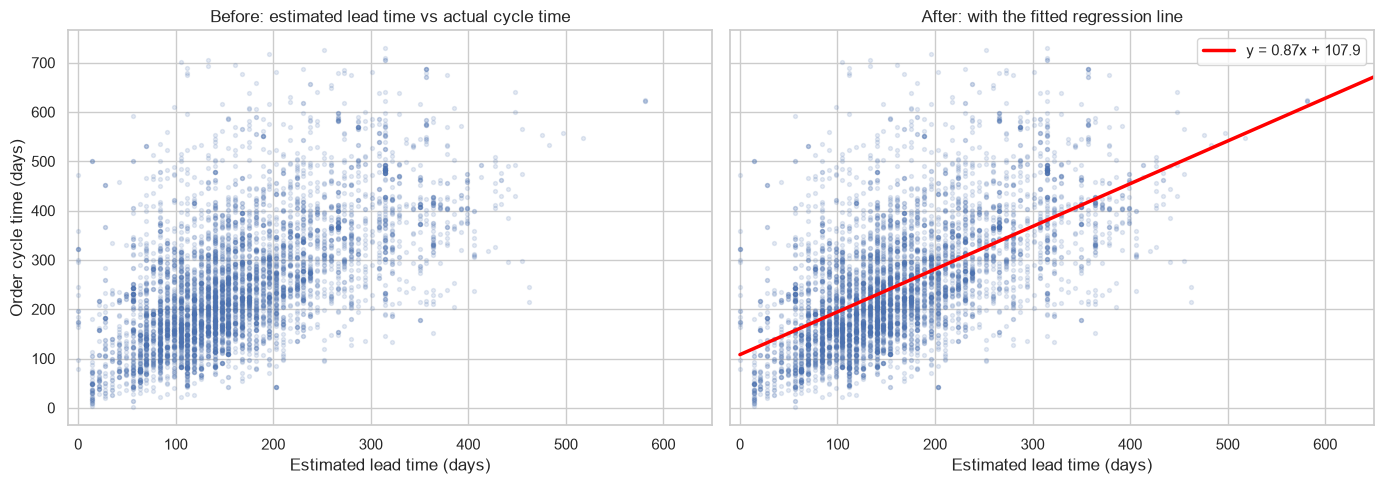

one-feature model test MSE: 10058.9


In [26]:
corr_with_target = data[["est_lead_time_days", "ordered_quantity", "unit_price", "order_year", "order_month",
                         TARGET]].corr()[TARGET].drop(TARGET)
top_feature = corr_with_target.abs().idxmax()
print("most correlated feature:", top_feature, round(corr_with_target[top_feature], 3))

one_feature_lr = LinearRegression().fit(X_train[[top_feature]], y_train)
# one order has an estimated lead time of 1,260 days and it squeezes the whole plot,
# so I only show the x axis up to 650 days
x_max = 650
print("test orders above", x_max, "days (not shown):", (X_test[top_feature] > x_max).sum())
x_line = np.linspace(0, x_max, 100).reshape(-1, 1)
y_line = one_feature_lr.predict(pd.DataFrame(x_line, columns=[top_feature]))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
axes[0].scatter(X_test[top_feature], y_test, alpha=0.15, s=8)
axes[0].set_title("Before: estimated lead time vs actual cycle time")
axes[0].set_xlabel("Estimated lead time (days)")
axes[0].set_ylabel("Order cycle time (days)")
axes[0].set_xlim(-10, x_max)

axes[1].scatter(X_test[top_feature], y_test, alpha=0.15, s=8)
axes[1].plot(x_line, y_line, color="red", linewidth=2.5,
             label=f"y = {one_feature_lr.coef_[0]:.2f}x + {one_feature_lr.intercept_:.1f}")
axes[1].set_title("After: with the fitted regression line")
axes[1].set_xlabel("Estimated lead time (days)")
axes[1].set_xlim(-10, x_max)
axes[1].legend()
plt.tight_layout()
plt.show()

print("one-feature model test MSE:", round(mean_squared_error(y_test, one_feature_lr.predict(X_test[[top_feature]])), 1))

**Before:** a clear upward trend, but the points are very spread out.

**After:** the fitted line is about y = 0.87x + 108. It follows the trend, but this one feature alone gives a test MSE of 10,059, which is why I need the other features.

## 12. Saving the best model

I save the preprocessing and the model together as one `Pipeline`, so the API can pass raw values. I also save the cleaned data in the API folder, because a random forest cannot continue training like SGD can. To retrain, it has to be fitted again on the old data plus the new rows.

In [27]:
best_model = models[best_name]
best_pipeline = Pipeline([("preprocess", preprocessor), ("model", best_model)])

MODEL_PATH = "../API/best_model.pkl"
joblib.dump(best_pipeline, MODEL_PATH, compress=3)
print(f"saved {best_name} to {MODEL_PATH} ({os.path.getsize(MODEL_PATH) / 1e6:.1f} MB)")

data.to_csv("../API/training_data.csv", index=False)
print("saved cleaned data:", data.shape)

saved Random forest to ../API/best_model.pkl (6.9 MB)
saved cleaned data: (29602, 13)


## 13. Predicting one row of the test set

This function loads the saved model and predicts the cycle time for one order, given as a one-row DataFrame or a dictionary. The API will reuse it.

In [28]:
def predict_cycle_time(row, model_path=MODEL_PATH):
    model = joblib.load(model_path)
    if isinstance(row, dict):
        row = pd.DataFrame([row])
    return float(model.predict(row[FEATURES])[0])


one_row = X_test.iloc[[0]]
display(one_row)

predicted = predict_cycle_time(one_row)
actual = y_test.iloc[0]
print(f"predicted: {predicted:.0f} days | actual: {actual} days | difference: {abs(predicted - actual):.0f} days")

,country,order_type,transport_mode,product_category,health_element,vendor_incoterm,destination_incoterm,ordered_quantity,unit_price,est_lead_time_days,order_year,order_month
4203,Italy,Purchase Order,Land,General Patient Care,Pandemic Influenza and Other Emerging Threats,DAP,DDP,1,4400.0,70.0,2021,12


predicted: 139 days | actual: 140 days | difference: 1 days


In [29]:
# same thing with a dictionary, which is what the API will receive
example = one_row.iloc[0].to_dict()
print(example)
print(round(predict_cycle_time(example), 1))

{'country': 'Italy', 'order_type': 'Purchase Order', 'transport_mode': 'Land', 'product_category': 'General Patient Care', 'health_element': 'Pandemic Influenza and Other Emerging Threats', 'vendor_incoterm': 'DAP', 'destination_incoterm': 'DDP', 'ordered_quantity': 1, 'unit_price': 4400.0, 'est_lead_time_days': 70.0, 'order_year': 2021, 'order_month': 12}


138.8


## 14. Limitations

- The test RMSE is about 64 days, and cycle times have a median of 229 days. So the prediction is good for planning in months, not for an exact date. The example above is only 1 day off, but that row is a lucky one.
- I removed the last year of orders, but the year before that could still be missing a few very slow deliveries.
- The data now ends in July 2023, so the model treats any newer order like a 2023 order.